# Plot DM density profiles
This notebook describes how to generate a radial/angular profile of the dark matter density previously generated with `CLUMPY`.

Authors: Gonzalo Rodriguez Fernandez gonzalo.rodriguez.fernandez@roma2.infn.it, Michele Doro michele.doro@unipd.it

Last update: 2024.03.04

#### General imports

In [18]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.offsetbox import AnchoredText
import pandas as pd
import numpy as np
import glob as glob
from scipy.interpolate import interp1d, make_interp_spline, BSpline

#### Definition of names and paths

In [19]:
df_input = pd.read_csv('Density_dsph_parameters.csv')

# dSph names
dSphNames = df_input['dSphNames'].values 

# Other parameters
# - distance kpc
# - Rtidal_einasto: tidal radius according to Einasto profile in kpc
# - Rtidal_burkert: tidal radius according to Burkert profile in kpc
distance       = df_input['distance'].values 
Rtidal_einasto = df_input['Rtidal_einasto'].values 
Rtidal_burkert = df_input['Rtidal_burkert'].values 
alpha_opt      = df_input['alpha_opt'].values 
chi2_Einasto = df_input['chi2_Einasto'].values 
chi2_Burkert = df_input['chi2_Burkert'].values 
channels = ['b','Tau']

alpha_Einasto_tidal = np.rad2deg(np.arctan(np.divide(Rtidal_einasto,distance)))
alpha_Burkert_tidal = np.rad2deg(np.arctan(np.divide(Rtidal_burkert,distance)))

df_input.head()

,Unnamed: 0,dSphNames,distance,Rtidal_einasto,Rtidal_burkert,alpha_opt,chi2_Einasto,chi2_Burkert
0,0,CBe,42,6.30,19.00,0.20,1.467308,1.439623
1,1,DraI,75,4.83,4.30,0.23,1.391558,1.389849
2,2,RetII,32,1.70,5.80,0.15,1.954545,1.800000
3,3,Scl,84,2.95,3.71,0.29,1.348967,1.347935
4,4,SgrII,67,3.70,4.20,0.06,1.978571,1.860000


In [20]:
# Define paths for astrophysical profiles
path = "../clumpy/DMdensity/"
!ls -l {path}

total 944
-rw-------@ 1 mdoro  staff  218476 Apr  9 12:32 dm_densityprofile_burkert.dat
-rw-r--r--@ 1 mdoro  staff   16623 May 15 12:20 dm_densityprofile_burkert_others.dat
-rw-------@ 1 mdoro  staff  220762 May 15 12:23 dm_densityprofile_einasto.dat
-rw-r--r--@ 1 mdoro  staff   16548 May 15 11:21 dm_densityprofile_einasto_others.dat


#### Just read the files and check output

In [21]:
df_BurkertDensity = pd.read_csv(path+'dm_densityprofile_burkert.dat',
                                sep='\s+',
                                comment='#'
                               )

df_EinastoDensity = pd.read_csv(path+'dm_densityprofile_einasto.dat',
                                sep='\s+',
                                comment='#'
                               )

In [22]:
df_EinastoDensity.head()

,r,CBe,CBe_UP,CBe_LO,DraI,DraI_UP,DraI_LO,RetII,RetII_UP,RetII_LO,...,SgrII_LO,UMaII,UMaII_UP,UMaII_LO,UMi,UMi_UP,UMi_LO,Wil1,Wil1_UP,Wil1_LO
0,0.010000,1.122669e+09,1.160773e+10,1.226039e+08,2.906693e+09,3.942236e+10,1.068990e+08,7.586620e+08,2.206547e+10,7.241738e+07,...,1.541062e+07,4.582692e+08,1.269956e+11,2.264909e+07,2.962026e+08,3.681699e+09,3.630421e+07,5.544407e+09,9.444026e+11,5.855536e+07
1,0.010233,1.121560e+09,1.156349e+10,1.224125e+08,2.863552e+09,3.859659e+10,1.061964e+08,7.555565e+08,2.191267e+10,7.207010e+07,...,1.527270e+07,4.566236e+08,1.250882e+11,2.256470e+07,2.956141e+08,3.662251e+09,3.627995e+07,5.447943e+09,9.291054e+11,5.698148e+07
2,0.010471,1.120436e+09,1.151905e+10,1.222172e+08,2.820807e+09,3.778535e+10,1.054906e+08,7.524186e+08,2.175982e+10,7.171759e+07,...,1.513352e+07,4.549627e+08,1.232009e+11,2.247885e+07,2.950195e+08,3.642758e+09,3.625527e+07,5.352309e+09,9.139907e+11,5.542288e+07
3,0.010715,1.119298e+09,1.147441e+10,1.220181e+08,2.778460e+09,3.698844e+10,1.047817e+08,7.492481e+08,2.160691e+10,7.135981e+07,...,1.499308e+07,4.532864e+08,1.213335e+11,2.239151e+07,2.944189e+08,3.623222e+09,3.623016e+07,5.257515e+09,8.990571e+11,5.388018e+07
4,0.010965,1.118145e+09,1.142957e+10,1.218150e+08,2.736509e+09,3.620567e+10,1.040699e+08,7.460450e+08,2.145396e+10,7.099670e+07,...,1.485141e+07,4.515946e+08,1.194861e+11,2.230268e+07,2.938121e+08,3.603643e+09,3.620462e+07,5.163567e+09,8.843037e+11,5.235398e+07


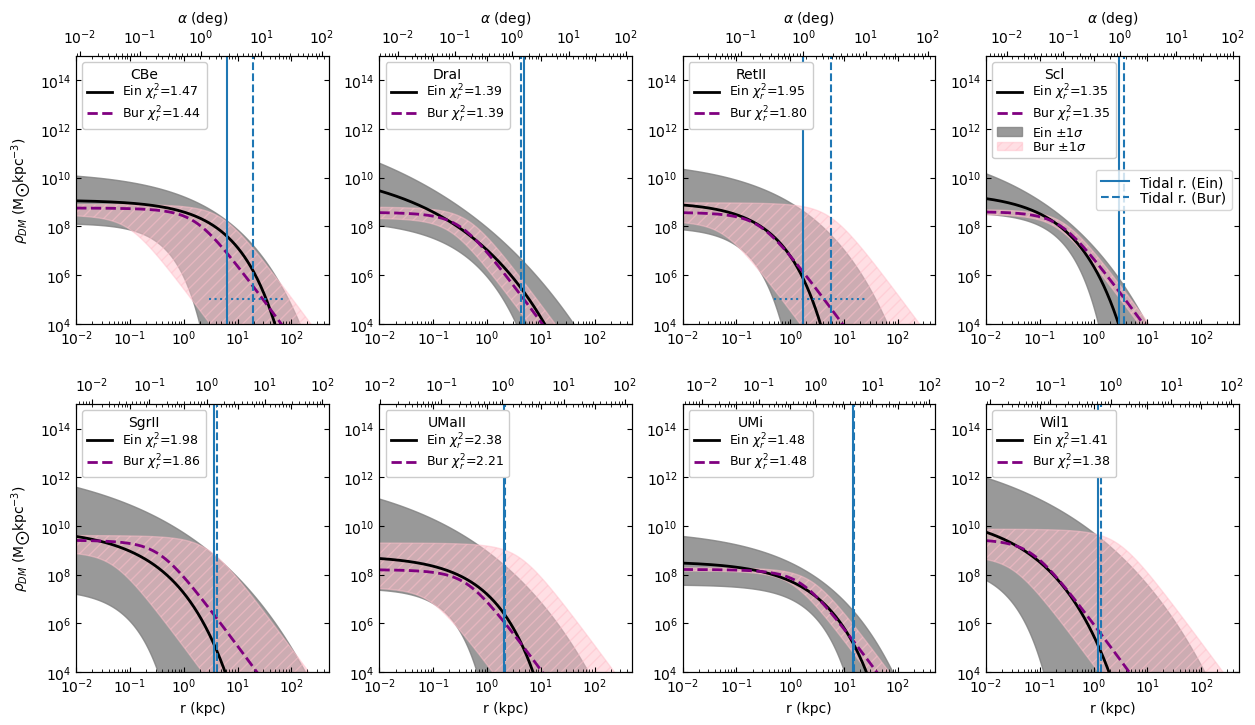

In [23]:
fig, ax_main = plt.subplots(2, 4, figsize=(15, 8))
plt.subplots_adjust(hspace=0.3)

counts = 1
for name, ax in zip(dSphNames, ax_main.flat):
    
   
    Rt_ein = Rtidal_einasto[counts-1]
    Rt_bur = Rtidal_burkert[counts-1]

    counts = counts + 1
    
    UP = name+'_UP'
    LO = name+'_LO'

    #print(name, UP, LO)
    if name == 'Scl':
        ax.plot(df_EinastoDensity['r'], df_EinastoDensity[name], linewidth=2, color='black',  
                label=r'Ein $\chi^2_{r}$='+'{:0.2f}'.format(round(chi2_Einasto[counts-2],2)))
        ax.plot(df_BurkertDensity['r'], df_BurkertDensity[name], linewidth=2, linestyle='--', color='purple',  
                label=r'Bur $\chi^2_{r}$='+'{:0.2f}'.format(round(chi2_Burkert[counts-2],2)))
        ax.fill_between(df_EinastoDensity['r'],
                        df_EinastoDensity[UP],
                        df_EinastoDensity[LO], color='grey',label=r"Ein $\pm1\sigma$", alpha=0.8)
        ax.fill_between(df_BurkertDensity['r'],
                        df_BurkertDensity[UP],
                        df_BurkertDensity[LO], color='pink', alpha=0.5, hatch='///',label=r"Bur $\pm1\sigma$")
    else:
        ax.plot(df_EinastoDensity['r'], df_EinastoDensity[name], linewidth=2, color='black',  
                label=r'Ein $\chi^2_{r}$='+'{:0.2f}'.format(round(chi2_Einasto[counts-2],2)))
        ax.plot(df_BurkertDensity['r'], df_BurkertDensity[name], linewidth=2, linestyle='--', color='purple',  
                label=r'Bur $\chi^2_{r}$='+'{:0.2f}'.format(round(chi2_Burkert[counts-2],2)))
        ax.fill_between(df_EinastoDensity['r'],
                        df_EinastoDensity[UP],
                        df_EinastoDensity[LO], color='grey', alpha=0.8)
        ax.fill_between(df_BurkertDensity['r'],
                        df_BurkertDensity[UP],
                        df_BurkertDensity[LO], color='pink', alpha=0.5, hatch='///')
    
    ax.axvline(x = Rt_ein, color = 'tab:blue', linestyle='-')
    ax.axvline(x = Rt_bur, color = 'tab:blue', linestyle='--')


    if name == 'CBe':
        ax.hlines(y = 1e5,  xmin=3, xmax=74, color = 'tab:blue', linestyle=':')

    if name == 'RetII':
        ax.hlines(y = 1e5, xmin=0.5, xmax=25.1, color = 'tab:blue', linestyle=':')
    
    if counts-1 == 1 or counts-1 == 5:
        ax.set_ylabel(r"$\rho_{DM}$ (M$_{\bigodot}$kpc$^{-3}$)", fontsize=10)


    # Compute a 2nd axis with distances instead of angles
    ax2 = ax.twiny()
    x_angle = np.rad2deg(np.arctan(np.divide(df_EinastoDensity['r'],distance[counts-2])))
    ax2.plot(x_angle,df_EinastoDensity[name], linewidth=0)
    ax2.loglog()

    if counts-1 <= 4:
        ax2.set_xlabel(r"$\alpha$ (deg)", fontsize=10)
    else:
        ax.set_xlabel(r"r (kpc)", fontsize=10)
        
    #ax.set_xlabel(r"r (kpc)", fontsize=10)
    ax.set_ylim(1e4, 1e15)
    ax.set_xlim(0.01,500)

    # Second legend for tidal radii
    if name == 'Scl':
        lines = ax.get_lines()
        legend2 = ax.legend([lines[i] for i in [2,3]], ["Tidal r. (Ein)", "Tidal r. (Bur)"], loc="center right", labelspacing=0.1)
        ax.add_artist(legend2)
   
    #plt.grid()
    legend = ax.legend(title=name, fontsize=9, loc='upper left', facecolor='white', framealpha=1, labelspacing=0.1)
    
    ax.loglog()
    ax.tick_params(which='both', direction='in', top=True, right=True)
    

#plt.savefig('plot_profiles_density_all.png', bbox_inches='tight', pad_inches=.3)
